# Part 2 – Clustering white wines (K-Means vs K-Medoids)

Unsupervised learning on the [Wine Quality (white) dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) from the UCI
Machine Learning Repository: 4,898 wines described by 11 physicochemical measurements.
The `quality` score is **not** used for clustering – the goal is to find natural groups in the chemistry alone.

Runs in Google Colab or locally (see `requirements.txt`).

## 1. Setup

In [1]:
import sys
if "google.colab" in sys.modules:  # pyclustering is not pre-installed on Colab
    %pip install -q pyclustering

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from pyclustering.cluster.kmedoids import kmedoids
from pyclustering.utils.metric import distance_metric, type_metric

warnings.filterwarnings("ignore", category=SyntaxWarning)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load the data

In [3]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
df = pd.read_csv(os.environ.get("WINE_CSV", URL), sep=";")
print(df.shape)
df.head()

(4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 3. Exploratory data analysis

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080


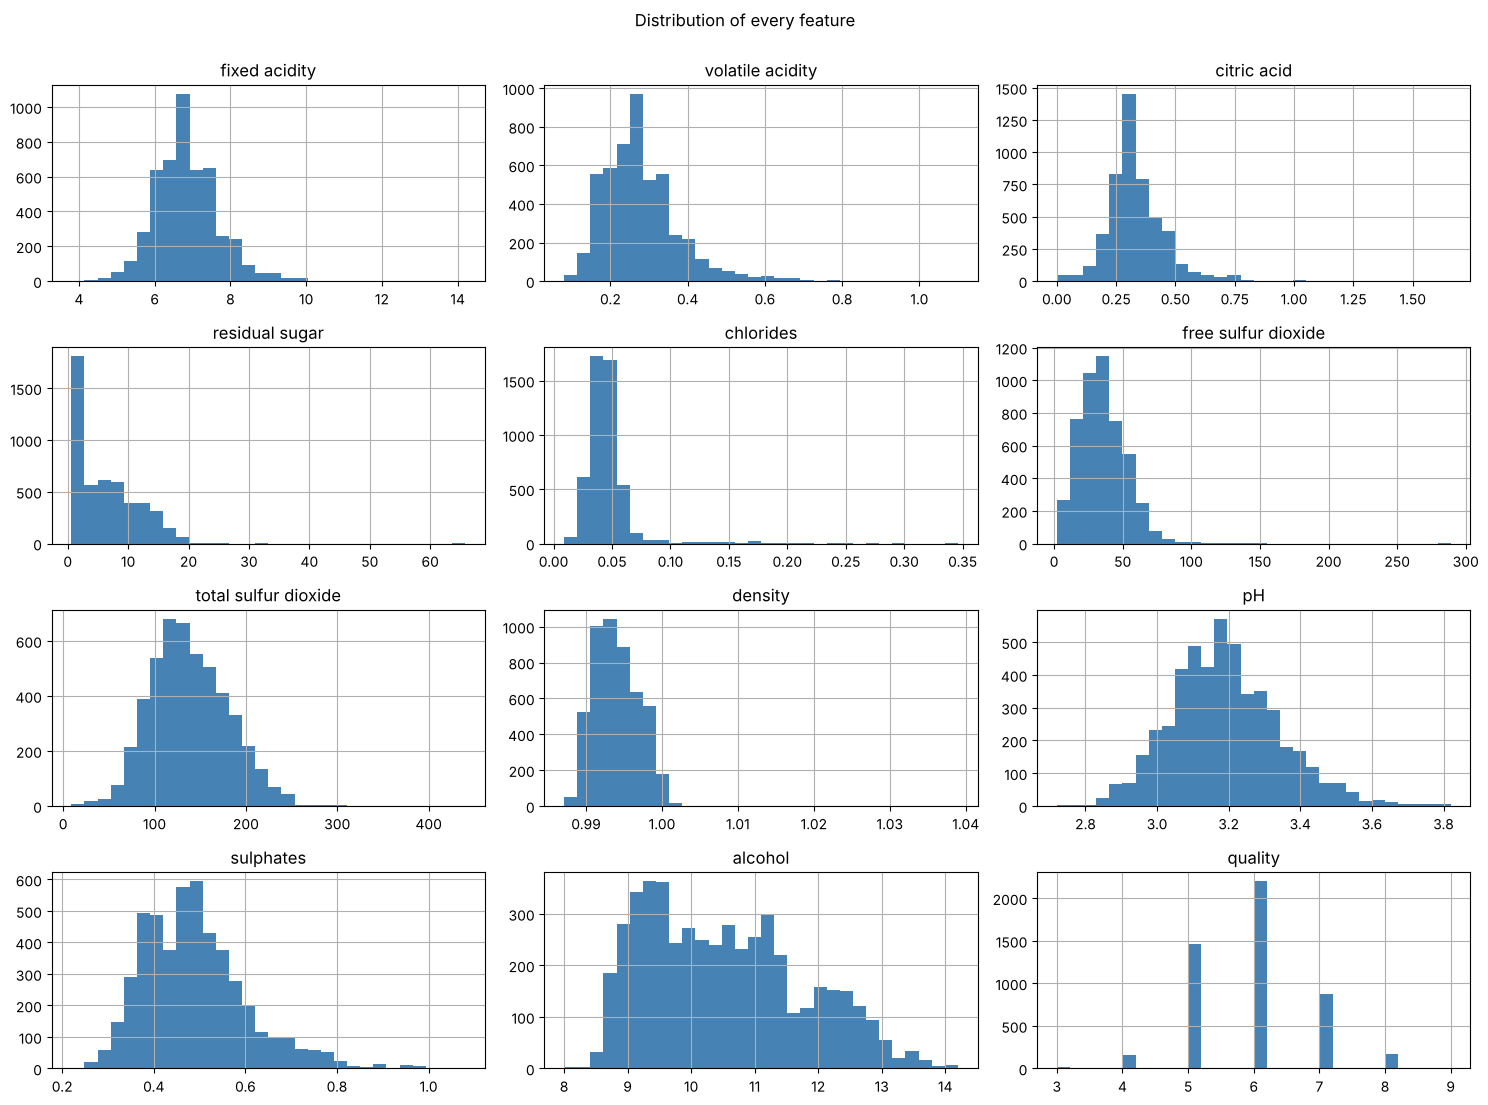

In [5]:
df.hist(bins=30, figsize=(15, 11), color="steelblue")
plt.suptitle("Distribution of every feature", y=1.0)
save("wine_histograms")

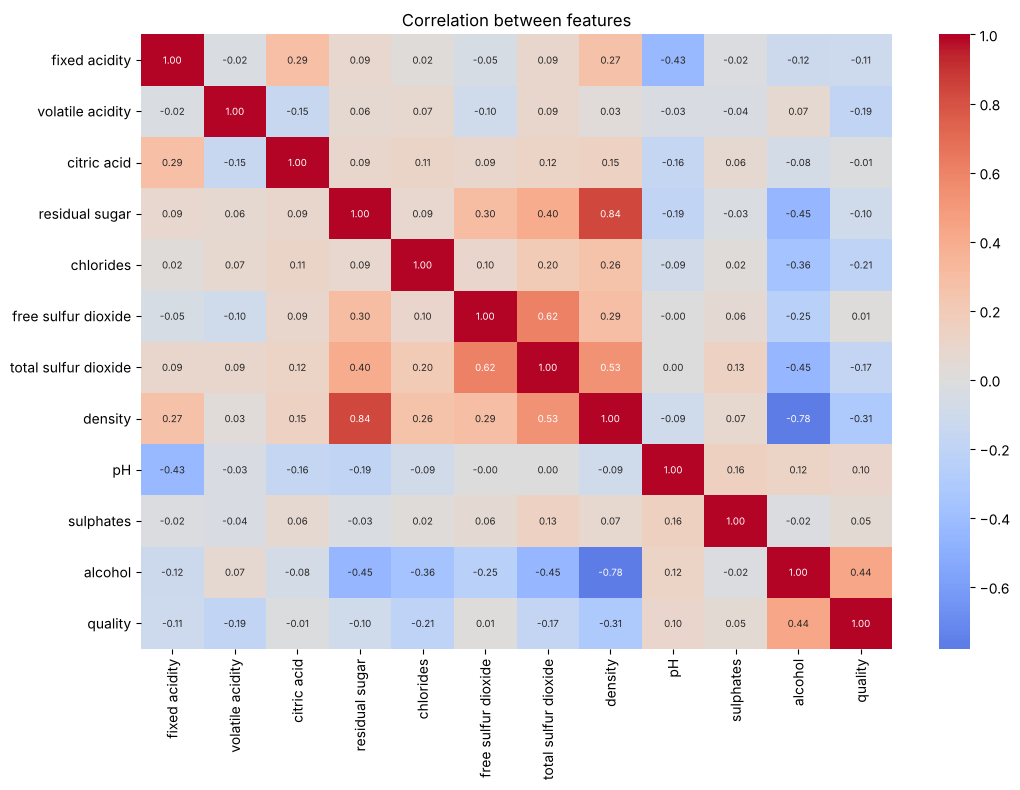

In [6]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation between features")
save("wine_correlation")

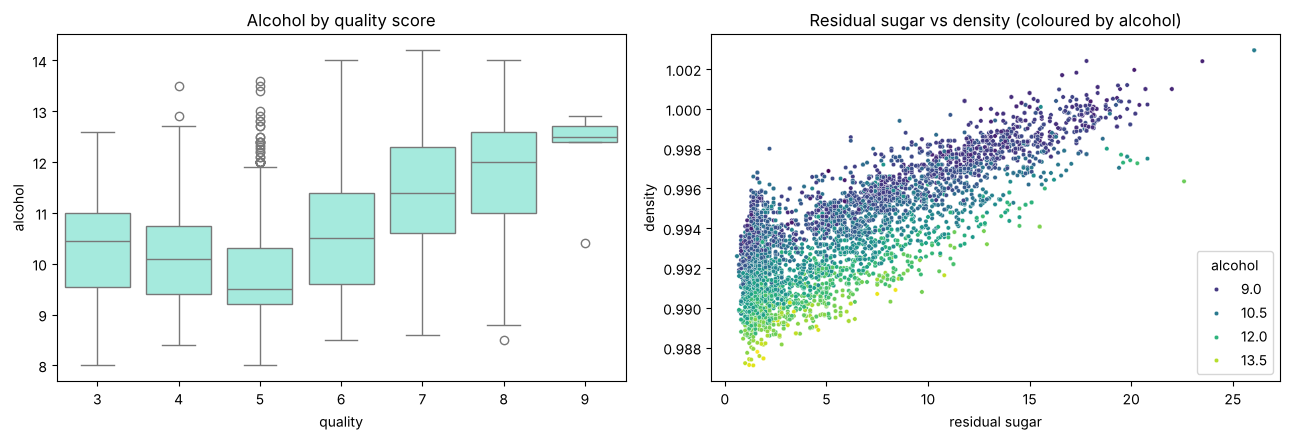

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="quality", y="alcohol", ax=axes[0], color="#99f6e4")
axes[0].set_title("Alcohol by quality score")
sns.scatterplot(data=df[df["residual sugar"] < 30], x="residual sugar", y="density", hue="alcohol",
                palette="viridis", s=10, ax=axes[1])
axes[1].set_title("Residual sugar vs density (coloured by alcohol)")
save("wine_relationships")

Findings: several features are skewed (residual sugar, chlorides, free sulfur dioxide), **density** is strongly linked to
residual sugar (+0.84) and alcohol (−0.78), and better wines tend to have more alcohol.

## 4. Pre-processing

Both algorithms measure distances, so every feature is standardised (z-score). Otherwise features with big numbers,
such as total sulfur dioxide, would dominate.

In [8]:
X = df.drop(columns="quality")
X_scaled = StandardScaler().fit_transform(X)

## 5. K-Means (k = 2 to 8)

In [9]:
k_values = list(range(2, 9))
kmeans_scores = []
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    kmeans_scores.append(silhouette_score(X_scaled, labels))
    print(f"K-Means   k={k}  silhouette={kmeans_scores[-1]:.4f}")

K-Means   k=2  silhouette=0.2145


K-Means   k=3  silhouette=0.1447


K-Means   k=4  silhouette=0.1589


K-Means   k=5  silhouette=0.1440


K-Means   k=6  silhouette=0.1466


K-Means   k=7  silhouette=0.1257


K-Means   k=8  silhouette=0.1238


## 6. K-Medoids (k = 2 to 8)

K-Medoids uses real wines as cluster centres, which makes it less sensitive to outliers than K-Means.

In [10]:
metric = distance_metric(type_metric.EUCLIDEAN)
kmedoid_scores = []
for k in k_values:
    model = kmedoids(X_scaled, list(range(k)), metric=metric)  # first k rows as starting medoids
    model.process()
    labels = np.zeros(len(X_scaled), dtype=int)
    for cluster_id, members in enumerate(model.get_clusters()):
        labels[members] = cluster_id
    kmedoid_scores.append(silhouette_score(X_scaled, labels))
    print(f"K-Medoids k={k}  silhouette={kmedoid_scores[-1]:.4f}")

K-Medoids k=2  silhouette=0.2041


K-Medoids k=3  silhouette=0.1199


K-Medoids k=4  silhouette=0.0981


K-Medoids k=5  silhouette=0.1014


K-Medoids k=6  silhouette=0.1111


K-Medoids k=7  silhouette=0.1077


K-Medoids k=8  silhouette=0.1018


## 7. Comparison

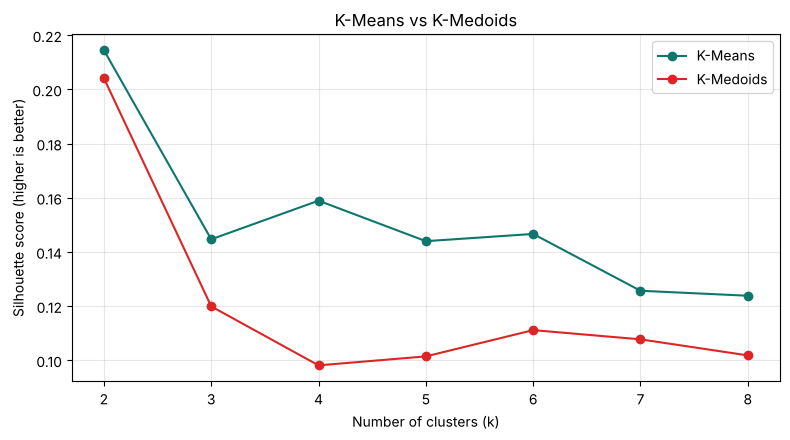

Best K-Means:   0.2145 (k=2)
Best K-Medoids: 0.2041 (k=2)
K-Means performed better.


In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means", color="#0f766e")
plt.plot(k_values, kmedoid_scores, marker="o", label="K-Medoids", color="#dc2626")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score (higher is better)")
plt.title("K-Means vs K-Medoids")
plt.grid(alpha=0.3)
plt.legend()
save("wine_silhouette_comparison")

best_k = k_values[int(np.argmax(kmeans_scores))]
print(f"Best K-Means:   {max(kmeans_scores):.4f} (k={best_k})")
print(f"Best K-Medoids: {max(kmedoid_scores):.4f} (k={k_values[int(np.argmax(kmedoid_scores))]})")
print("K-Means performed better." if max(kmeans_scores) > max(kmedoid_scores) else "K-Medoids performed better.")

## 8. Visualising the clusters with PCA

PCA squeezes the 11 features into 2 so the clusters can be plotted. The chosen *k* is the one with the best K-Means silhouette score.

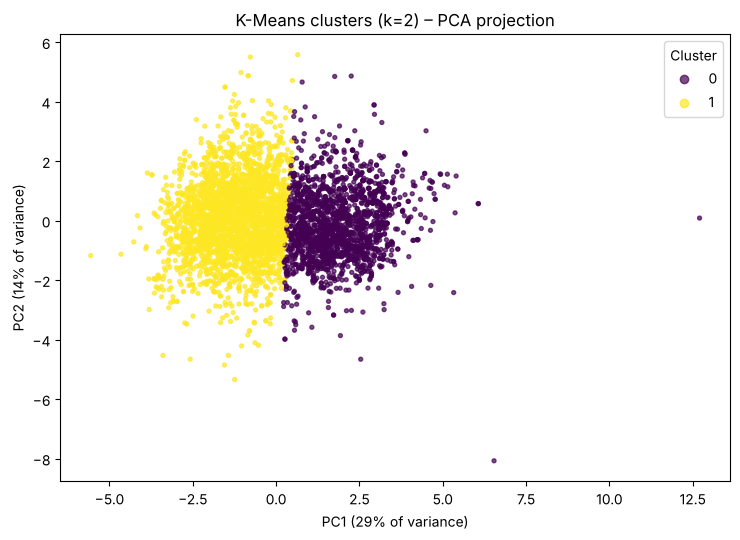

In [12]:
final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = final.fit_predict(X_scaled)

pca = PCA(n_components=2)
reduced = pca.fit_transform(X_scaled)

plt.figure(figsize=(7.5, 5.5))
sc = plt.scatter(reduced[:, 0], reduced[:, 1], c=clusters, cmap="viridis", s=8, alpha=0.7)
plt.legend(*sc.legend_elements(), title="Cluster")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title(f"K-Means clusters (k={best_k}) – PCA projection")
save("wine_kmeans_pca")

## 9. What do the clusters mean?

Comparing the average chemistry of each cluster turns the result into something a winemaker could use.

In [13]:
profile = df.assign(cluster=clusters).groupby("cluster").mean().round(3)
profile.insert(0, "wines", np.bincount(clusters))
profile.T

cluster,0,1
wines,1957.000,2941.000
fixed acidity,7.003,6.756
volatile acidity,0.283,0.275
citric acid,0.363,0.315
residual sugar,10.692,3.530
chlorides,0.054,0.040
free sulfur dioxide,45.465,28.549
total sulfur dioxide,170.898,116.710
density,0.997,0.992
pH,3.158,3.209


## 10. Conclusion

- **K-Means beats K-Medoids** at every value of k, so the centroid-based approach suits this data, which has few extreme outliers.
- The best silhouette score is around **0.21 at k = 2**. That is a weak score: the wines form two broad, overlapping groups
  rather than clearly separated clusters, which is common for continuous chemical measurements.
- The cluster profiles show the split is mainly **sweeter, denser, lower-alcohol wines vs drier, higher-alcohol wines**,
  and the second group has a higher average quality score.
- Next steps: try DBSCAN or Gaussian Mixture Models, and a better K-Medoids start (e.g. k-medoids++), and remove skew with log transforms before clustering.